In [3]:
import pandas as pd
import numpy as np

# Load the credit risk dataset
df = pd.read_csv('credit_risk_dataset.csv')

# Print basic shape and structure
print("Dataset loaded successfully!")
print(f"Total Rows: {df.shape[0]}, Total Columns: {df.shape[1]}")

FileNotFoundError: [Errno 2] No such file or directory: 'credit_risk_dataset.csv'

In [4]:
!pip install pandas numpy matplotlib seaborn


[notice] A new release of pip is available: 24.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import numpy as np

# Load dataset using your exact folder path
file_path = r'D:\Python\archive (1)\credit_risk_dataset.csv'
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print(f"Total Rows: {df.shape[0]}, Total Columns: {df.shape[1]}")

Dataset loaded successfully!
Total Rows: 32581, Total Columns: 12


In [5]:
# Check missing values per column
print("=== Missing Values ===")
missing = df.isnull().sum()
print(missing[missing > 0])

# Inspect summary statistics for age and loan attributes
print("\n=== Summary Statistics ===")
print(df[['person_age', 'person_income', 'loan_amnt', 'loan_int_rate']].describe())

=== Missing Values ===
person_emp_length     895
loan_int_rate        3116
dtype: int64

=== Summary Statistics ===
         person_age  person_income     loan_amnt  loan_int_rate
count  32581.000000   3.258100e+04  32581.000000   29465.000000
mean      27.734600   6.607485e+04   9589.371106      11.011695
std        6.348078   6.198312e+04   6322.086646       3.240459
min       20.000000   4.000000e+03    500.000000       5.420000
25%       23.000000   3.850000e+04   5000.000000       7.900000
50%       26.000000   5.500000e+04   8000.000000      10.990000
75%       30.000000   7.920000e+04  12200.000000      13.470000
max      144.000000   6.000000e+06  35000.000000      23.220000


In [6]:
# 1. Remove impossible age outliers (e.g., age >= 100)
df_clean = df[df['person_age'] < 100].copy()

# 2. Impute missing interest rates with the median interest rate for that loan grade
df_clean['loan_int_rate'] = df_clean.groupby('loan_grade')['loan_int_rate'].transform(
    lambda x: x.fillna(x.median())
)

# 3. Impute missing employment length with median
df_clean['person_emp_length'] = df_clean['person_emp_length'].fillna(
    df_clean['person_emp_length'].median()
)

# Verify cleaning
print("Cleaning complete!")
print("Remaining missing values:", df_clean.isnull().sum().sum())

Cleaning complete!
Remaining missing values: 0


In [7]:
# Baseline default rate
overall_default = df_clean['loan_status'].mean() * 100
print(f"Overall Default Rate: {overall_default:.2f}%\n")

# Calculate default rate and average interest rate by Loan Grade
grade_summary = df_clean.groupby('loan_grade').agg(
    total_loans=('loan_status', 'count'),
    default_rate=('loan_status', lambda x: x.mean() * 100),
    avg_interest_rate=('loan_int_rate', 'mean')
).reset_index()

print("=== Risk Profile by Loan Grade ===")
print(grade_summary.to_string(index=False))

Overall Default Rate: 21.82%

=== Risk Profile by Loan Grade ===
loan_grade  total_loans  default_rate  avg_interest_rate
         A        10777      9.956389           7.342761
         B        10448     16.280628          10.994983
         C         6456     20.740397          13.465245
         D         3626     59.045780          15.357022
         E          964     64.419087          16.993143
         F          241     70.539419          18.600851
         G           64     98.437500          20.244375


C:\Users\tiya4\AppData\Local\Temp\ipykernel_24948\2545860853.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\tiya4\AppData\Local\Temp\ipykernel_24948\2545860853.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\tiya4\AppData\Local\Temp\ipykernel_24948\2545860853.py:29: UserWarning: FixedFormatter should only be used together with FixedLocator
  axes[1].set_xticklabels(['Paid Back (0)', 'Defaulted (1)'])


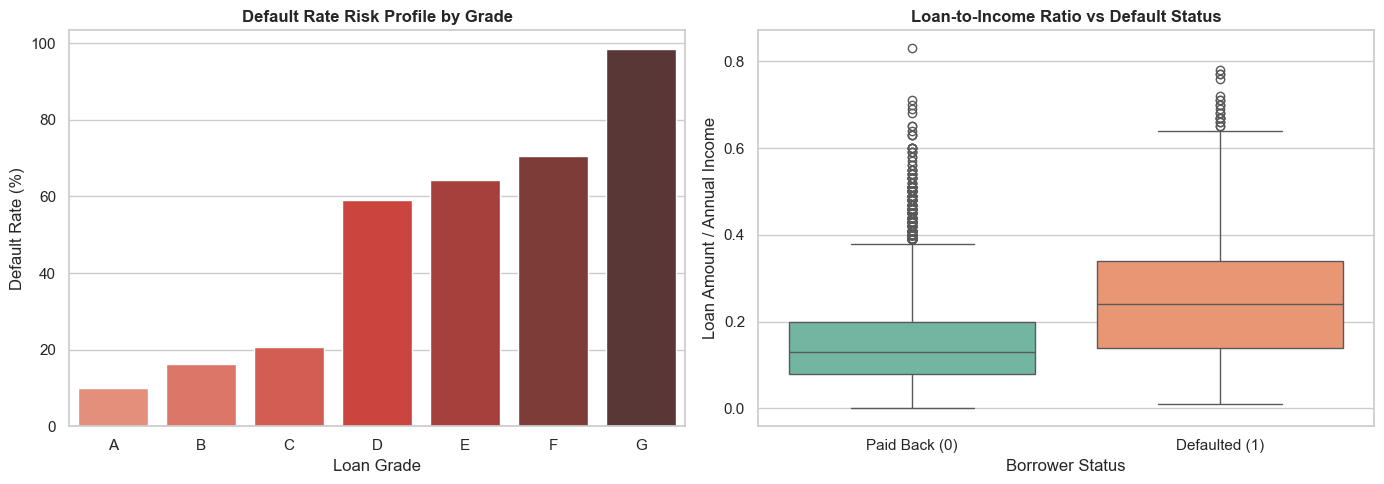

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set clean aesthetic style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Default Rate by Risk Grade
sns.barplot(
    data=grade_summary, 
    x='loan_grade', 
    y='default_rate', 
    palette='Reds_d', 
    ax=axes[0]
)
axes[0].set_title('Default Rate Risk Profile by Grade', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Loan Grade')
axes[0].set_ylabel('Default Rate (%)')

# Chart 2: Loan Amount to Income Ratio vs Default Status
sns.boxplot(
    data=df_clean, 
    x='loan_status', 
    y='loan_percent_income', 
    palette='Set2', 
    ax=axes[1]
)
axes[1].set_title('Loan-to-Income Ratio vs Default Status', fontsize=12, fontweight='bold')
axes[1].set_xticklabels(['Paid Back (0)', 'Defaulted (1)'])
axes[1].set_xlabel('Borrower Status')
axes[1].set_ylabel('Loan Amount / Annual Income')

plt.tight_layout()
plt.show()

In [11]:
!pip install "numpy<2" --force-reinstall

     ---------------------------------------- 0.0/61.0 kB ? eta -:--:--
     ---------------------------------------- 61.0/61.0 kB 3.2 MB/s eta 0:00:00
   ---------------------------------------- 0.0/15.8 MB ? eta -:--:--
   - -------------------------------------- 0.8/15.8 MB 24.4 MB/s eta 0:00:01
   ------ --------------------------------- 2.5/15.8 MB 32.4 MB/s eta 0:00:01
   ----------- ---------------------------- 4.4/15.8 MB 35.3 MB/s eta 0:00:01
   --------------- ------------------------ 5.9/15.8 MB 31.5 MB/s eta 0:00:01
   ------------------- -------------------- 7.8/15.8 MB 33.2 MB/s eta 0:00:01
   ------------------------- -------------- 10.0/15.8 MB 35.5 MB/s eta 0:00:01
   ------------------------------- -------- 12.4/15.8 MB 40.9 MB/s eta 0:00:01
   ------------------------------------- -- 14.8/15.8 MB 43.7 MB/s eta 0:00:01
   ------------------------------------- -- 14.9/15.8 MB 36.4 MB/s eta 0:00:01
   ------------------------------------- -- 15.0/15.8 MB 32.8 MB/s eta 0

  You can safely remove it manually.
  You can safely remove it manually.

[notice] A new release of pip is available: 24.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


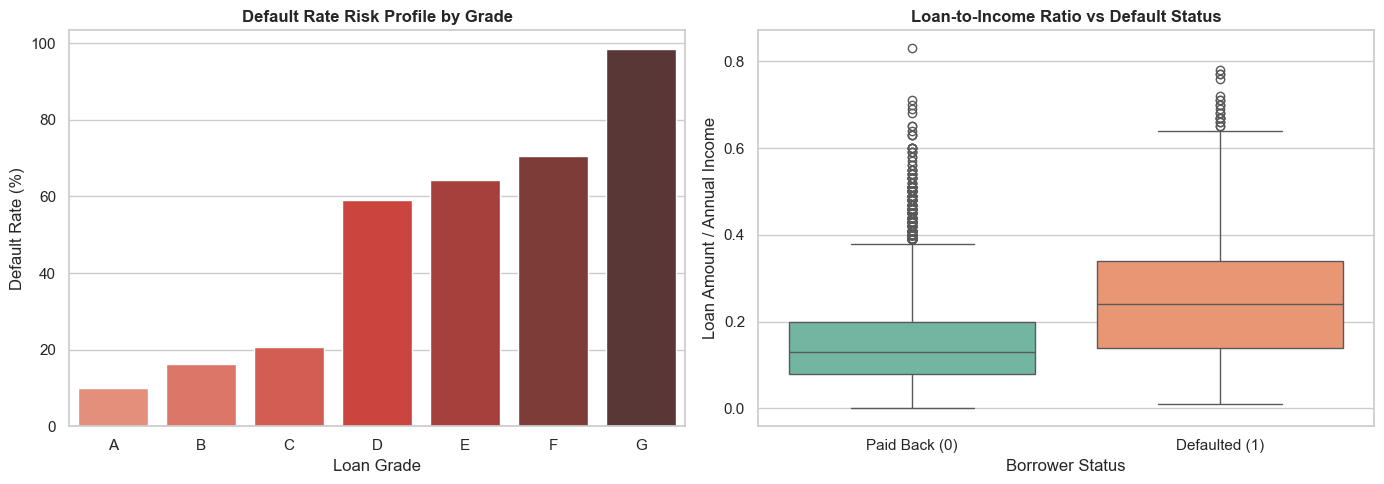

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Default Rate by Risk Grade (updated hue/legend parameters)
sns.barplot(
    data=grade_summary, 
    x='loan_grade', 
    y='default_rate', 
    hue='loan_grade',
    palette='Reds_d', 
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Default Rate Risk Profile by Grade', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Loan Grade')
axes[0].set_ylabel('Default Rate (%)')

# Chart 2: Loan Amount to Income Ratio vs Default Status
sns.boxplot(
    data=df_clean, 
    x='loan_status', 
    y='loan_percent_income', 
    hue='loan_status',
    palette='Set2', 
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Loan-to-Income Ratio vs Default Status', fontsize=12, fontweight='bold')
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Paid Back (0)', 'Defaulted (1)'])
axes[1].set_xlabel('Borrower Status')
axes[1].set_ylabel('Loan Amount / Annual Income')

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# Load dataset using absolute path
file_path = r'D:\P                                                                                          ython\archive (1)\credit_risk_dataset.csv'
df = pd.read_csv(file_path)

print(f"Data successfully loaded! Shape: {df.shape}")
df.head()

Data successfully loaded! Shape: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


--- 1. Loading & Cleaning Data ---
Data cleaned. Total samples: 32,576

--- 2. Feature Engineering ---
Engineered 4 new financial pressure metrics successfully.


C:\Users\tiya4\AppData\Local\Temp\ipykernel_4576\218358698.py:64: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()



--- 3. Training & Benchmarking Models ---

               Model  ROC-AUC  Recall (Default Detection)  Precision
Logistic Regression   0.8780                      0.7968     0.5442
      Random Forest   0.9290                      0.7511     0.8834
            XGBoost   0.9489                      0.7947     0.8352

--- 4. Financial Cost-Benefit Optimization (XGBoost) ---
Standard Threshold (0.50) Loss : $3,041,509.09
Optimal Threshold (0.20) Loss  : $2,362,475.22
Potential Loss Reduction    : $679,033.87


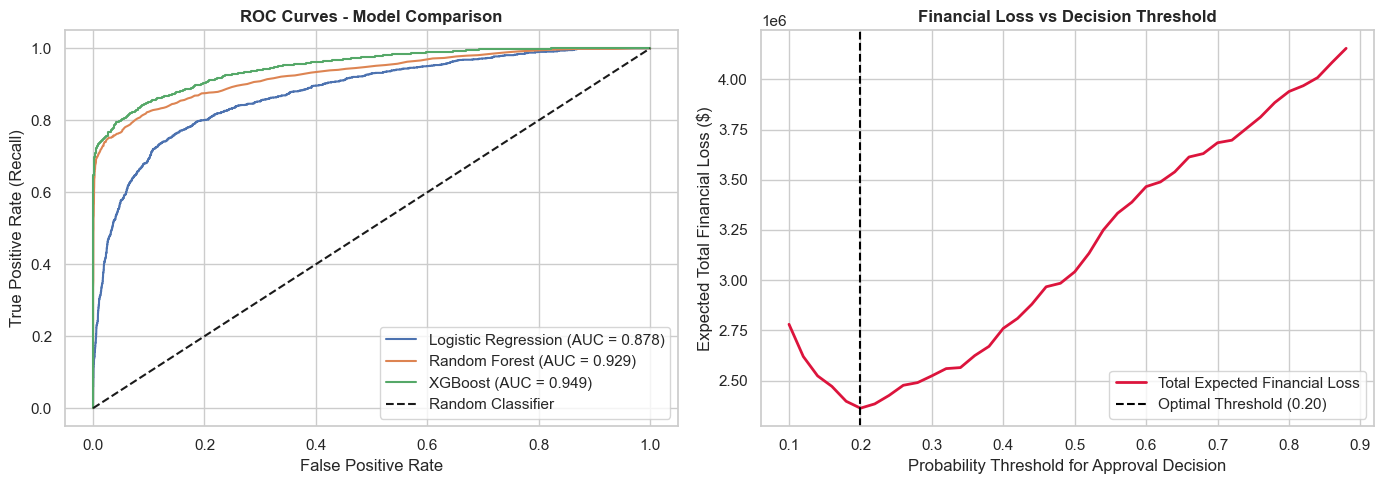

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report, 
    roc_auc_score, 
    confusion_matrix, 
    roc_curve,
    precision_recall_curve
)

# Set random seed for reproducibility
SEED = 42

# -----------------------------------------------------------------------------
# STEP 1: LOAD DATA & CLEANING
# -----------------------------------------------------------------------------
print("--- 1. Loading & Cleaning Data ---")
# Using raw string (r'...') to properly handle Windows backslashes
file_path = r'D:\Python\archive (1)\credit_risk_dataset.csv'
df = pd.read_csv(file_path)

# Handle missing values
df['person_emp_length'] = df['person_emp_length'].fillna(df['person_emp_length'].median())
df['loan_int_rate'] = df['loan_int_rate'].fillna(df['loan_int_rate'].median())

# Remove age outliers (> 100 years old)
df_clean = df[df['person_age'] <= 100].copy()
print(f"Data cleaned. Total samples: {len(df_clean):,}")

# -----------------------------------------------------------------------------
# STEP 2: FEATURE ENGINEERING
# -----------------------------------------------------------------------------
print("\n--- 2. Feature Engineering ---")

# Leverage & Interest Burdens
df_clean['debt_to_income_ratio'] = df_clean['loan_amnt'] / df_clean['person_income']
df_clean['annual_interest_cost'] = df_clean['loan_amnt'] * (df_clean['loan_int_rate'] / 100)
df_clean['interest_to_income_ratio'] = df_clean['annual_interest_cost'] / df_clean['person_income']

# Credit History Length Relative to Adult Age
adult_age = np.maximum(df_clean['person_age'] - 18, 1)
df_clean['credit_hist_ratio'] = df_clean['cb_person_cred_hist_length'] / adult_age

print("Engineered 4 new financial pressure metrics successfully.")

# -----------------------------------------------------------------------------
# STEP 3: TRAIN / TEST SPLIT & PREPROCESSING PIPELINE
# -----------------------------------------------------------------------------
X = df_clean.drop(columns=['loan_status'])
y = df_clean['loan_status']

# Categorical vs Numerical features
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
    ]
)

# Fit preprocessor on training data
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

# Calculate class balance ratio for XGBoost weighting
scale_pos_weight = (len(y_train) - sum(y_train)) / sum(y_train)

# -----------------------------------------------------------------------------
# STEP 4: MULTI-MODEL COMPARISON
# -----------------------------------------------------------------------------
print("\n--- 3. Training & Benchmarking Models ---")

models = {
    "Logistic Regression": LogisticRegression(class_weight='balanced', max_iter=1000, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=SEED, n_jobs=-1),
    "XGBoost": XGBClassifier(scale_pos_weight=scale_pos_weight, eval_metric='logloss', random_state=SEED)
}

comparison_results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train_prep, y_train)
    trained_models[name] = model
    
    y_pred = model.predict(X_test_prep)
    y_proba = model.predict_proba(X_test_prep)[:, 1]
    
    auc = roc_auc_score(y_test, y_proba)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    
    recall = tp / (tp + fn)       # Ability to detect actual defaults
    precision = tp / (tp + fp)    # Accuracy of default predictions
    
    comparison_results.append({
        "Model": name,
        "ROC-AUC": round(auc, 4),
        "Recall (Default Detection)": round(recall, 4),
        "Precision": round(precision, 4)
    })

benchmark_df = pd.DataFrame(comparison_results)
print("\n", benchmark_df.to_string(index=False))

# -----------------------------------------------------------------------------
# STEP 5: BUSINESS THRESHOLD OPTIMIZATION (COST-BENEFIT ANALYSIS)
# -----------------------------------------------------------------------------
print("\n--- 4. Financial Cost-Benefit Optimization (XGBoost) ---")

best_model = trained_models["XGBoost"]
y_proba_best = best_model.predict_proba(X_test_prep)[:, 1]

# Average loan metrics for financial impact calculations
avg_loan_amnt = df_clean['loan_amnt'].mean()
avg_interest = df_clean['annual_interest_cost'].mean()

# Cost Matrix Assumptions:
# - False Negative (Missing default) = Loss of principal (~$9,500)
# - False Positive (Rejecting solvent borrower) = Missed interest revenue (~$1,100)
cost_fn = avg_loan_amnt
cost_fp = avg_interest

thresholds = np.arange(0.1, 0.9, 0.02)
costs = []

for thresh in thresholds:
    y_pred_thresh = (y_proba_best >= thresh).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_thresh).ravel()
    total_cost = (fn * cost_fn) + (fp * cost_fp)
    costs.append(total_cost)

optimal_idx = np.argmin(costs)
optimal_threshold = thresholds[optimal_idx]
min_cost = costs[optimal_idx]

print(f"Standard Threshold (0.50) Loss : ${costs[np.abs(thresholds - 0.5).argmin()]:,.2f}")
print(f"Optimal Threshold ({optimal_threshold:.2f}) Loss  : ${min_cost:,.2f}")
print(f"Potential Loss Reduction    : ${costs[np.abs(thresholds - 0.5).argmin()] - min_cost:,.2f}")

# -----------------------------------------------------------------------------
# STEP 6: VISUALIZATIONS
# -----------------------------------------------------------------------------
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: ROC Curves
for name, model in trained_models.items():
    y_proba = model.predict_proba(X_test_prep)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, y_proba):.3f})")

axes[0].plot([0, 1], [0, 1], 'k--', label='Random Classifier')
axes[0].set_title('ROC Curves - Model Comparison', fontsize=12, fontweight='bold')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].legend()

# Plot 2: Cost Curve Optimization
axes[1].plot(thresholds, costs, color='crimson', linewidth=2, label='Total Expected Financial Loss')
axes[1].axvline(optimal_threshold, color='black', linestyle='--', label=f'Optimal Threshold ({optimal_threshold:.2f})')
axes[1].set_title('Financial Loss vs Decision Threshold', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Probability Threshold for Approval Decision')
axes[1].set_ylabel('Expected Total Financial Loss ($)')
axes[1].legend()

plt.tight_layout()
plt.show()